# Process sims
Processes a sim_telarray production (see `README.md`) into calibrations (pedestals, pedvars, flat gain), cleaned images
and Hillas parameters per telescope, like the data (see `heap.process_simulation.process_simulation()`), with
diagnostics of the inputs and of what gets written. No event cuts or reconstruction: see `explore_sims.ipynb`.

Output goes to `<processed_dir>/<name>/<tag>/`; rerunning reuses it if it was processed with the same settings and raises if not (see
`<name>_processing.json`), unless `REPROCESS`.

# Imports

In [1]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from heap import process_simulation as ps
from heap.parameterize import TAB10_COLORS
from run_simulation import load_config

# Globals

In [ ]:
CONFIG = Path("../configs/simulation.yaml") # relative to simulation_tools/; or a production's <output_dir>/slurm/<job>.yaml
cfg = load_config(CONFIG)

OUTPUT_DIR = cfg["paths"]["output_dir"]
NAME = cfg["production"]["name"]
TAG = cfg["sim_telarray"]["tag"]
SIMTEL_FILES = sorted(glob.glob(str(OUTPUT_DIR / "simtel" / TAG / f"{NAME}_run*.simtel.zst")))
if cfg["paths"]["processed_dir"] is None:
    raise ValueError(f"set paths.processed_dir in {CONFIG}: where processed sims go, outside the (maybe shared) output_dir")
PROCESSED_DIR = cfg["paths"]["processed_dir"] / NAME / TAG
REPROCESS = False # rerun image processing even if PROCESSED_DIR already has this production (needed if its settings differ)

# image processing
IMAGE_THRESHOLD = 4.0
BORDER_THRESHOLD = 2.0
KEEP_BRIGHTEST_ISLAND = True

# plotting
N_IMAGES = 8 # example images per telescope

# Runs
Each run's pointing and what was simulated (`heap.read_simtel.read_run_header()`), and its file size.

In [3]:
runs = ps.run_table(SIMTEL_FILES)
header = runs.iloc[0]
TELESCOPES = [f"T{tel_id}" for tel_id in header.tel_id]
COLORS = {name: TAB10_COLORS[i] for i, name in enumerate(TELESCOPES)}

print(f"{NAME} ({TAG}): {len(runs)} runs, {(runs.n_showers * runs.n_use).sum()} events simulated, {runs.MB.sum():.0f} MB")
print(f"pointing alt {runs.alt.min():.2f}-{runs.alt.max():.2f}, az {runs.az.min():.2f}-{runs.az.max():.2f} deg")
print(f"energy {header.energy_range[0]:g}-{header.energy_range[1]:g} TeV, index {header.spectral_index:g}, "
      f"cores within {header.core_range[1]:g} m, viewcone {header.viewcone[0]:g}-{header.viewcone[1]:g} deg")
runs[["alt", "az", "n_showers", "n_use", "MB"]]

gamma_pointlike (v1): 1000 runs, 500000 events simulated, 243 MB
pointing alt 70.00-70.00, az 191.03-191.03 deg
energy 3-1000 TeV, index -2.7, cores within 500 m, viewcone 0-0 deg


,alt,az,n_showers,n_use,MB
run,,,,,
1,69.999992,191.029984,100,5,0.247012
2,69.999992,191.029984,100,5,0.233474
3,69.999992,191.029984,100,5,0.230575
4,69.999992,191.029984,100,5,0.234471
5,69.999992,191.029984,100,5,0.242228
...,...,...,...,...,...
996,69.999992,191.029984,100,5,0.231493
997,69.999992,191.029984,100,5,0.232029
998,69.999992,191.029984,100,5,0.251191


# Image processing
Skipped if `PROCESSED_DIR` already has this production processed with the same settings; raises if it was processed
with other settings, unless `REPROCESS`.

In [4]:
ps.process_simulation(
    SIMTEL_FILES, PROCESSED_DIR, NAME, image_threshold=IMAGE_THRESHOLD, border_threshold=BORDER_THRESHOLD,
    keep_brightest_island=KEEP_BRIGHTEST_ISLAND, reprocess=REPROCESS,
);

  Telescope 1: pedestal and pedvar from 10000 pedestal frames, flat gain, 263 images
  Telescope 2: pedestal and pedvar from 10000 pedestal frames, flat gain, 217 images
  Telescope 3: pedestal and pedvar from 10000 pedestal frames, flat gain, 227 images
  Telescope 4: pedestal and pedvar from 10000 pedestal frames, flat gain, 234 images
  Telescope 5: pedestal and pedvar from 10000 pedestal frames, flat gain, 254 images
  Telescope 6: pedestal and pedvar from 10000 pedestal frames, flat gain, 279 images
  Telescope 7: pedestal and pedvar from 10000 pedestal frames, flat gain, 245 images


# Diagnostics

## Processed data
Every telescope written: its images (triggered), the fraction with any pixel left after cleaning, and the camera's
median pedestal and pedvar.

In [5]:
ps.product_table(PROCESSED_DIR, NAME, TELESCOPES)

,Images,Cleaned,Pedestal,Pedvar,Settings
Telescope,,,,,
T1,263,1.0,-0.073935,6.740075,"{'nsig': 5.0, 'fit_gaussian': True, 'x': None,..."
T2,217,1.0,-0.059342,6.742161,"{'nsig': 5.0, 'fit_gaussian': True, 'x': None,..."
T3,227,1.0,-0.071783,6.738107,"{'nsig': 5.0, 'fit_gaussian': True, 'x': None,..."
T4,234,1.0,-0.067538,6.742496,"{'nsig': 5.0, 'fit_gaussian': True, 'x': None,..."
T5,254,1.0,-0.067852,6.736293,"{'nsig': 5.0, 'fit_gaussian': True, 'x': None,..."
T6,279,1.0,-0.068185,6.748384,"{'nsig': 5.0, 'fit_gaussian': True, 'x': None,..."
T7,245,1.0,-0.068175,6.746749,"{'nsig': 5.0, 'fit_gaussian': True, 'x': None,..."


## Calibrations
Each telescope's pedestal and pedvar maps, from its pedestal frames pooled over every run (see
`heap.make_pedestals.calculate_pedestal_and_pedvar()`). The gain is flat (1).

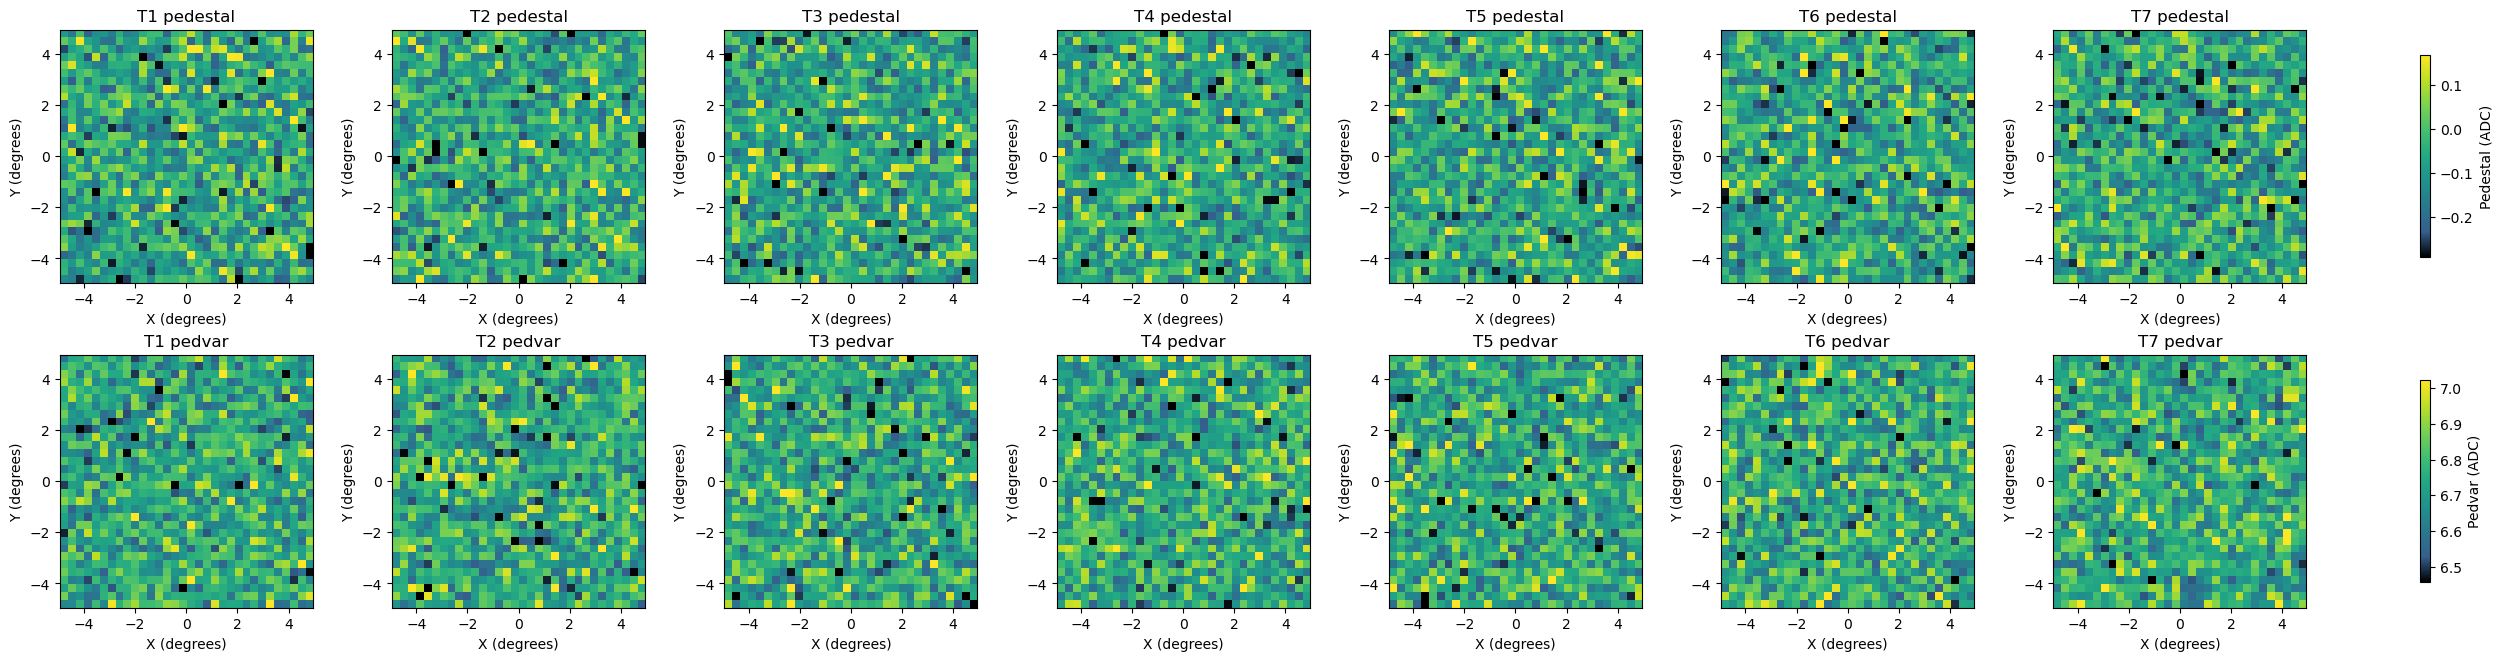

In [6]:
ps.plot_calibrations(PROCESSED_DIR, NAME, TELESCOPES)
plt.show()

## Triggers
Events per telescope combination and images per event, before any cuts (events matched by `Run` and `EventID`, see
`heap.process_simulation.load_events()`).

1450 triggered events, 1719 images


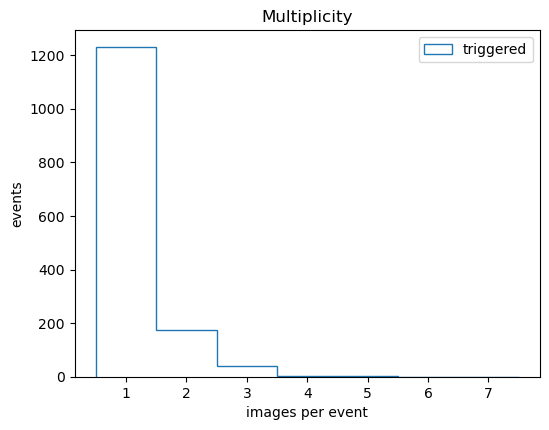

,events
Telescope,
T5,237
T4,224
T6,172
T2,161
T1,149
T3,147
T7,142
T6 + T7,53
T1 + T3,35


In [7]:
images, showers = ps.load_events(PROCESSED_DIR, NAME, runs, TELESCOPES)
print(f"{len(showers)} triggered events, {len(images)} images")
ps.plot_multiplicity({"triggered": images}, len(TELESCOPES))
plt.show()
images.groupby("Event").Telescope.agg(lambda t: " + ".join(sorted(t))).value_counts().to_frame("events")

## Images
`N_IMAGES` random cleaned images per telescope with their Hillas ellipse. Run the cell again for others.

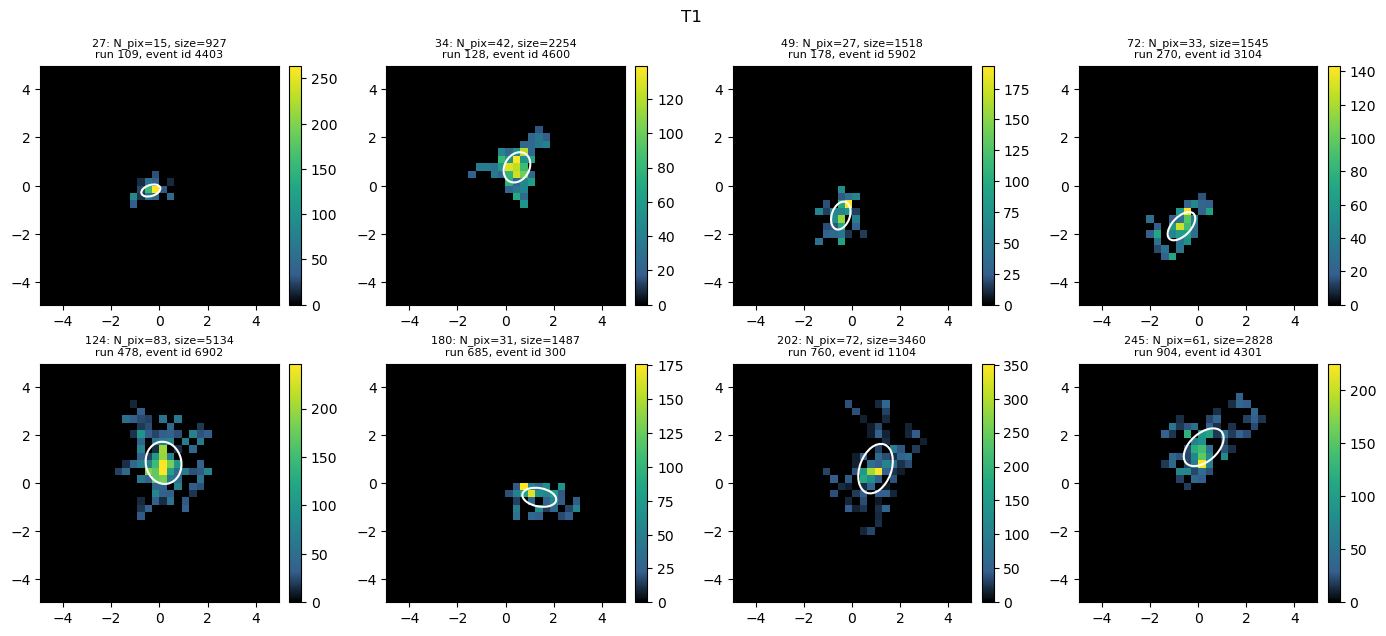

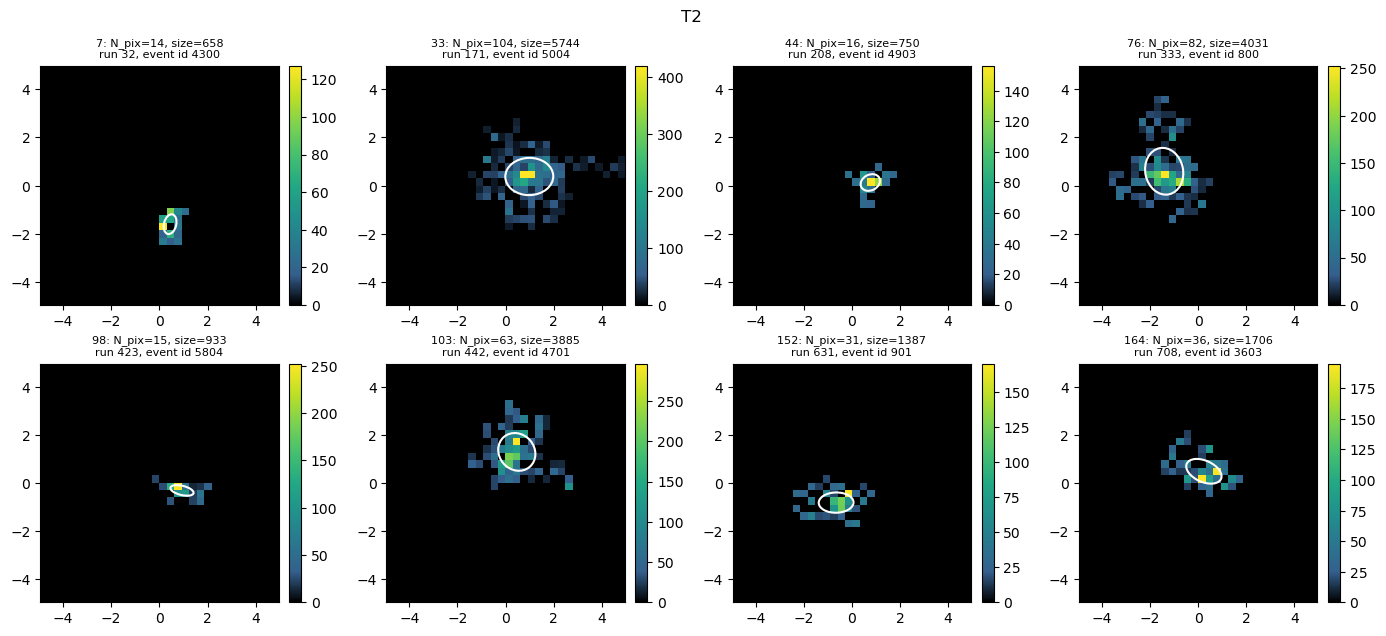

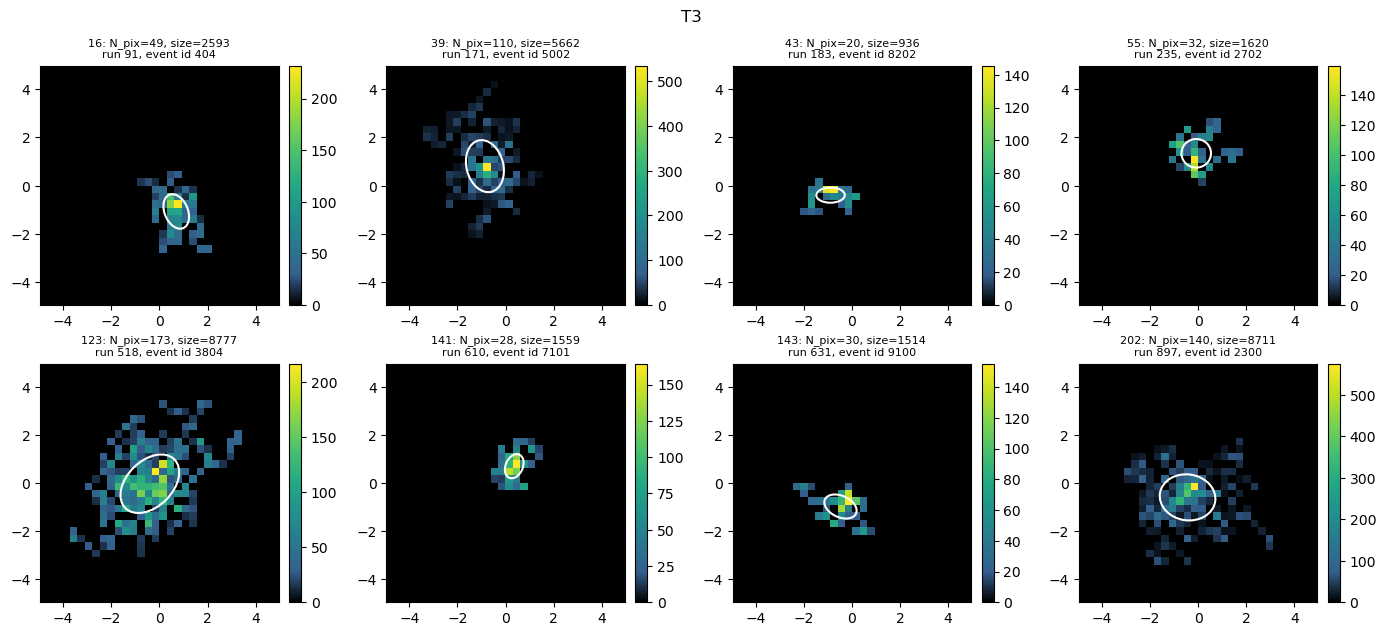

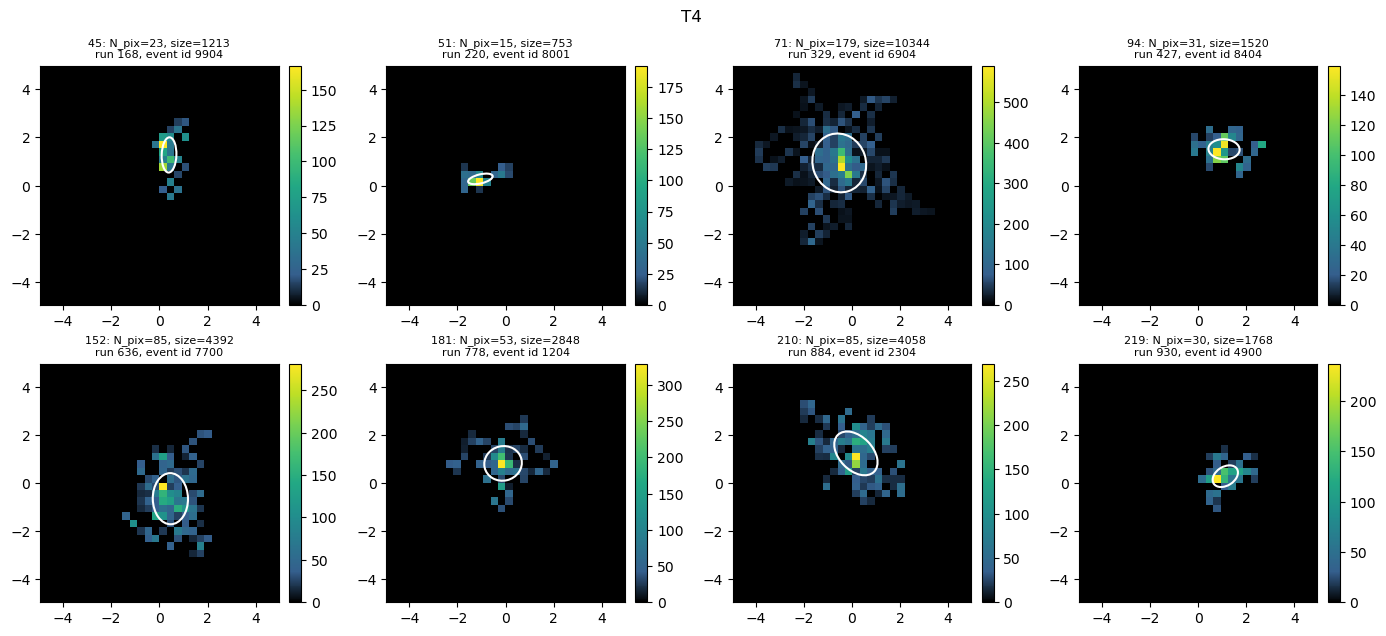

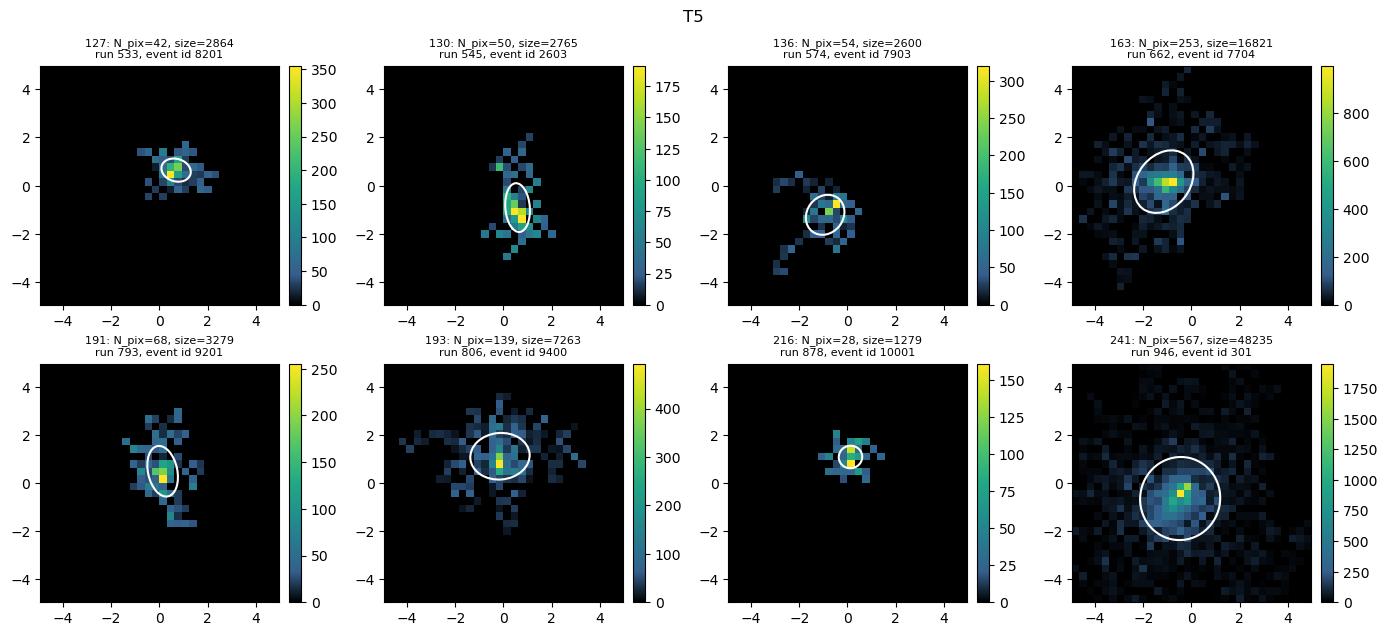

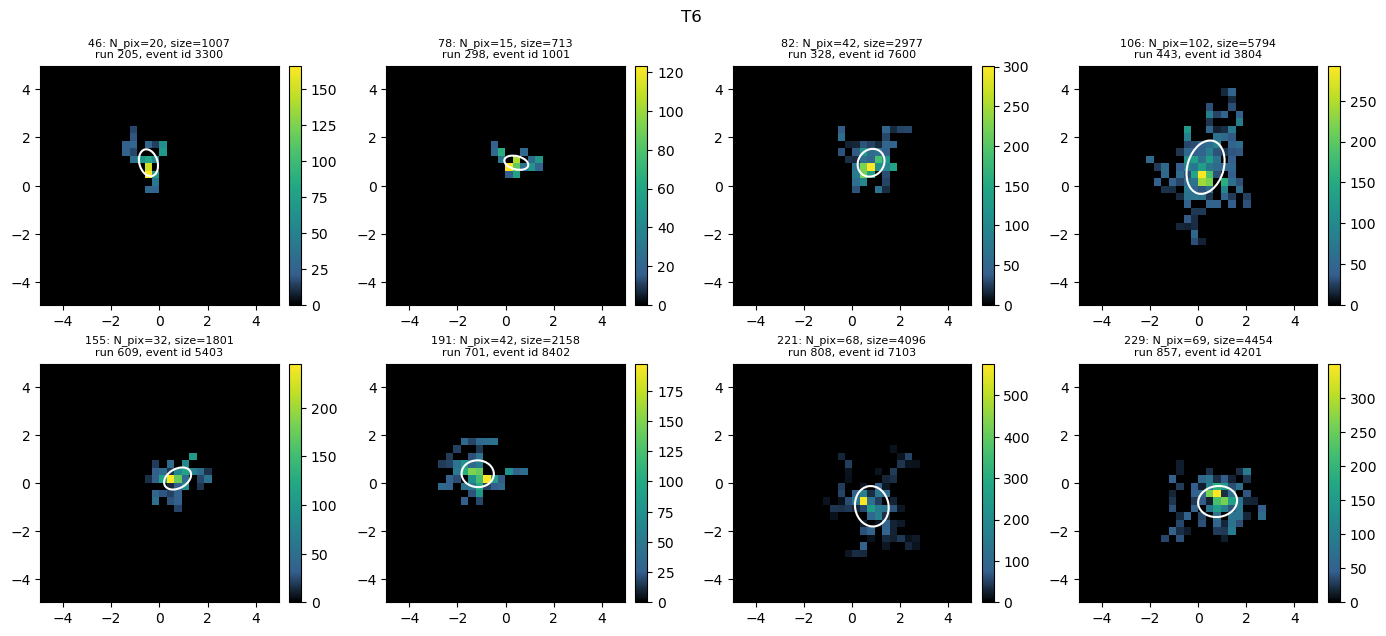

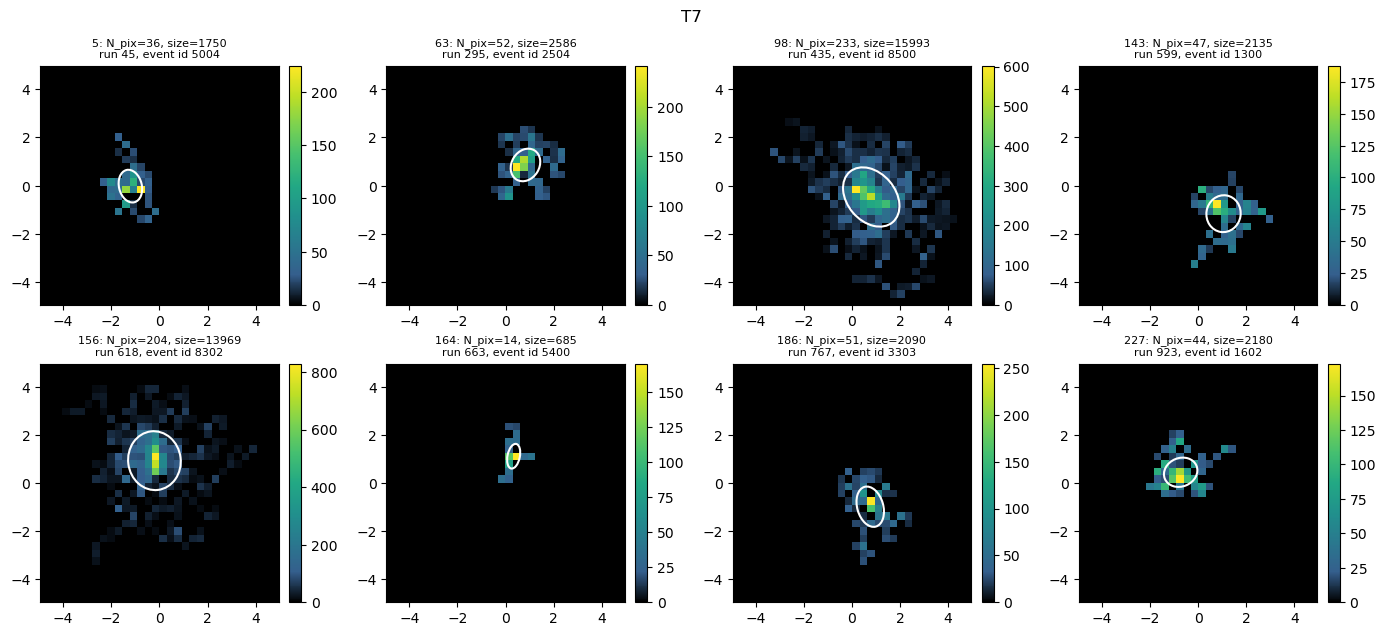

In [8]:
rng = np.random.default_rng()
for name, tel in images.groupby("Telescope"):
    ps.plot_image_grid(PROCESSED_DIR, NAME, name, np.sort(rng.choice(tel.ImageIndex, size=min(N_IMAGES, len(tel)), replace=False)))
    plt.show()